# 02 - Eksperimen & Komparasi 5 Model (*From Scratch* vs `scikit-learn`)
**Penanggung Jawab:** Kolektif Seluruh Anggota (Anggota 1 - 5)  
**Kelompok:** G15 - MessiLearning (IF3170 Inteligensi Artifisial)

---
Notebook ini berisi pengujian 5 algoritma Supervised Learning *from scratch* menggunakan data sintetis (selama fase paralel) maupun data bersih hasil `DataPipeline`, lengkap dengan komparasi metrik (Akurasi, Presisi, Recall, F1-Score, Waktu Eksekusi) terhadap `scikit-learn`.

In [6]:
import os
import sys
import time
import numpy as np
import pandas as pd
from scipy.stats import chi2

sys.path.append(os.path.abspath('..'))

from src.utils import (
    set_global_seed,
    RANDOM_SEED,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    calculate_custom_cost,
    k_fold_split,
)
from src.dummy_generator import generate_clean_synthetic_data, generate_dtl_synthetic_data
from src.knn import KNN
from src.dtl import DecisionTree, export_tree_visualization
from src.logistic_regression import LogisticRegression
from src.logistic_contour import generate_loss_contour_video
from src.svm import SVM, plot_svm_margin_2d
from src.naive_bayes import NaiveBayes, export_bayesian_network_graph

def macro_f1_score(y_true, y_pred):
    return 0.5 * (f1_score(y_true, y_pred) + f1_score(1 - y_true, 1 - y_pred))

def mcnemar_test(y_true, pred_a, pred_b):
    """Uji McNemar berpasangan dengan koreksi kontinuitas Edwards."""
    correct_a = pred_a == y_true
    correct_b = pred_b == y_true
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    statistic = ((abs(b - c) - 1.0) ** 2) / (b + c) if (b + c) else 0.0
    p_value = float(1.0 - chi2.cdf(statistic, df=1)) if (b + c) else 1.0
    return b, c, statistic, p_value

set_global_seed(RANDOM_SEED)
X_dummy, y_dummy = generate_clean_synthetic_data(n_samples=500, n_features=6)
X_dtl_dummy, y_dtl_dummy = generate_dtl_synthetic_data(n_samples=500)
print(f"Dummy Clean Shape: {X_dummy.shape}, Dummy DTL Shape: {X_dtl_dummy.shape}")

Dummy Clean Shape: (500, 6), Dummy DTL Shape: (500, 4)


## 1. K-Nearest Neighbors (KNN) —  Anggota 1 (13524042)
Komparasi `src.knn.KNN` vs `sklearn.neighbors.KNeighborsClassifier`. Melakukan hyperparameter tuning untuk distance (Euclidean/Manhattan) dan kandidat `k=1..50` melalui stratified inner holdout. Validation dipakai untuk laporan metrik dan confusion matrix. 

Referensi:
- `[1]` Mata Kuliah ITB IF3170 Inteligensi Artifisial, "k-Nearest Neighbor (KNN)".
- `[2]` GeeksForGeeks, "Vectorization in NumPy with Practical Examples". https://www.geeksforgeeks.org/numpy/vectorized-operations-in-numpy/
- `[3]` Ayoosh Kathuria. "Nuts and Bolts of NumPy Optimization Part 1: Understanding Vectorization and Broadcasting". https://blog.paperspace.com/numpy-optimization-vectorization-and-broadcasting/


=== PENCARIAN k DAN DISTANCE (INNER HOLDOUT DARI TRAIN) ===


Distance        euclidean                 manhattan             
Implementasi From scratch scikit-learn From scratch scikit-learn
k                                                               
1                  0.7694       0.7694       0.7772       0.7772
2                  0.7454       0.7593       0.7516       0.7577
3                  0.7776       0.7776       0.7827       0.7827
4                  0.7730       0.7664       0.7846       0.7687
5                  0.7874       0.7872       0.7880       0.7880
6                  0.7839       0.7811       0.7860       0.7838
7                  0.7903       0.7903       0.7916       0.7916
8                  0.7889       0.7759       0.7917       0.7779
9                  0.7816       0.7816       0.7895       0.7895
10                 0.7943       0.7762       0.7938       0.7770
11                 0.7822       0.7822       0.7857       0.7857
12                 0.7890       0.7783       0.7897       0.7810
13                 0.7885       0.7885       0.7832       0.7832
14                 0.7923       0.7779       0.7870       0.7771
15                 0.7819       0.7819       0.7793       0.7793
16                 0.7828       0.7736       0.7871       0.7786
17                 0.7814       0.7814       0.7821       0.7821
18                 0.7844       0.7768       0.7860       0.7744
19                 0.7754       0.7754       0.7808       0.7808
20                 0.7809       0.7704       0.7854       0.7728
21                 0.7781       0.7781       0.7792       0.7792
22                 0.7812       0.7743       0.7791       0.7738
23                 0.7808       0.7808       0.7769       0.7769
24                 0.7825       0.7723       0.7827       0.7690
25                 0.7794       0.7794       0.7747       0.7747
26                 0.7849       0.7698       0.7801       0.7704
27                 0.7796       0.7796       0.7755       0.7755
28                 0.7810       0.7692       0.7818       0.7727
29                 0.7751       0.7751       0.7772       0.7772
30                 0.7788       0.7712       0.7785       0.7732
31                 0.7745       0.7745       0.7751       0.7751
32                 0.7796       0.7700       0.7782       0.7713
33                 0.7746       0.7746       0.7741       0.7741
34                 0.7759       0.7693       0.7812       0.7688
35                 0.7753       0.7753       0.7748       0.7748
36                 0.7745       0.7710       0.7783       0.7729
37                 0.7716       0.7716       0.7780       0.7780
38                 0.7717       0.7672       0.7800       0.7701
39                 0.7698       0.7698       0.7755       0.7755
40                 0.7717       0.7714       0.7753       0.7683
41                 0.7721       0.7721       0.7730       0.7730
42                 0.7746       0.7671       0.7753       0.7675
43                 0.7674       0.7674       0.7703       0.7703
44                 0.7719       0.7650       0.7726       0.7663
45                 0.7686       0.7686       0.7667       0.7667
46                 0.7714       0.7663       0.7701       0.7659
47                 0.7682       0.7682       0.7674       0.7674
48                 0.7674       0.7678       0.7724       0.7650
49                 0.7673       0.7673       0.7686       0.7686
50                 0.7700       0.7655       0.7698       0.7634

euclidean / From scratch: k=10 | Macro F1=0.7943
euclidean / scikit-learn: k=7 | Macro F1=0.7903
manhattan / From scratch: k=10 | Macro F1=0.7938
manhattan / scikit-learn: k=7 | Macro F1=0.7916
=== VALIDATION METRICS + CONFUSION MATRIX COUNTS ===


,Distance,Implementasi,k terbaik,Tuning Macro F1,Accuracy,Precision,Recall,Macro F1,Cost (2FP+FN),TN,FP,FN,TP,Val predict time (s)
0,euclidean,From scratch,10,0.7943,0.8173,0.7264,0.7093,0.7913,1476.0,3195,478,520,1269,65.8243
1,euclidean,scikit-learn,7,0.7903,0.8253,0.7554,0.6903,0.7971,1354.0,3273,400,554,1235,2.9612
2,manhattan,From scratch,10,0.7938,0.8186,0.7339,0.6998,0.7915,1445.0,3219,454,537,1252,63.5286
3,manhattan,scikit-learn,7,0.7916,0.8239,0.7592,0.6769,0.7941,1346.0,3289,384,578,1211,7.9237


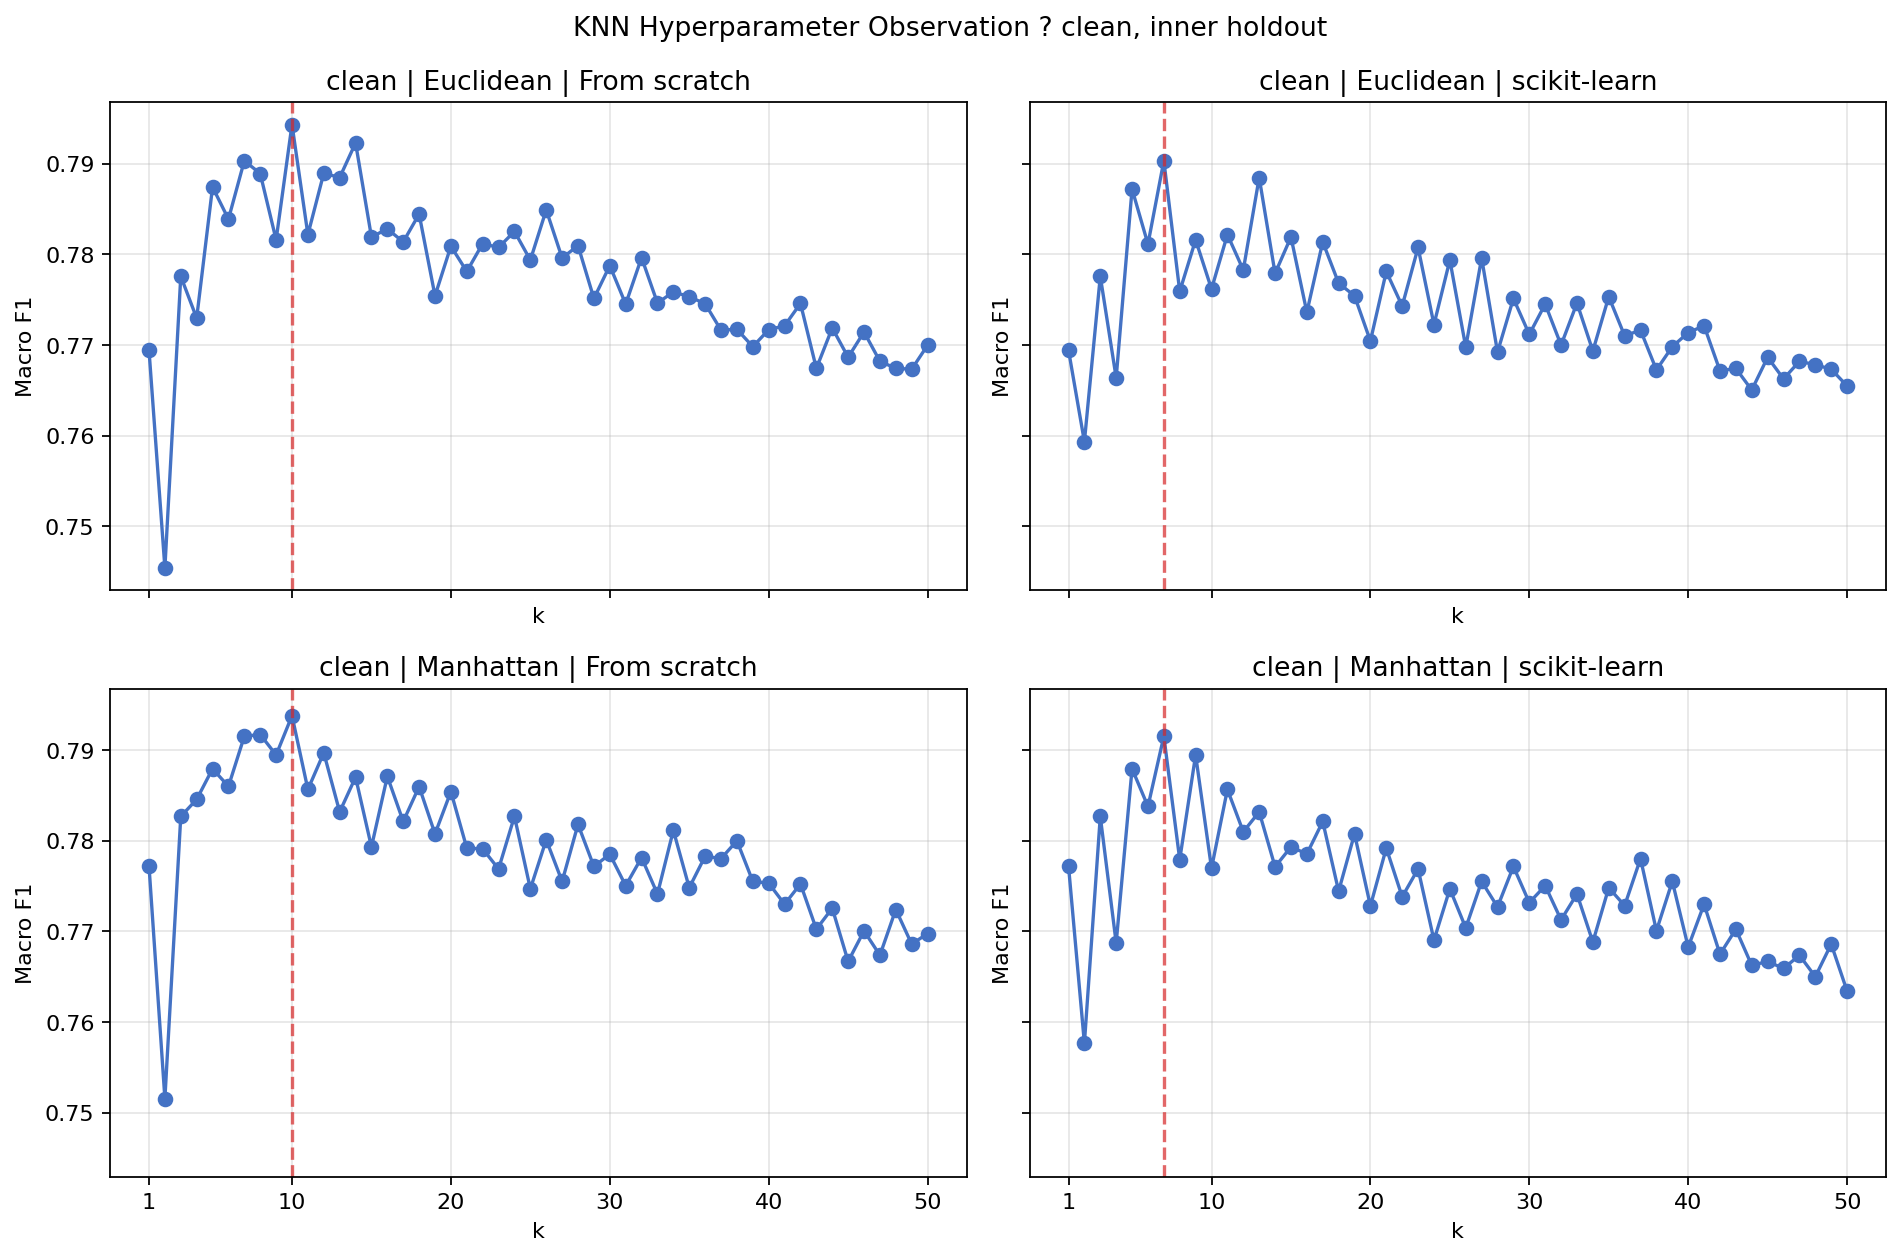

[Tuning Plot Saved] ..\output\plots\knn_k_search.png


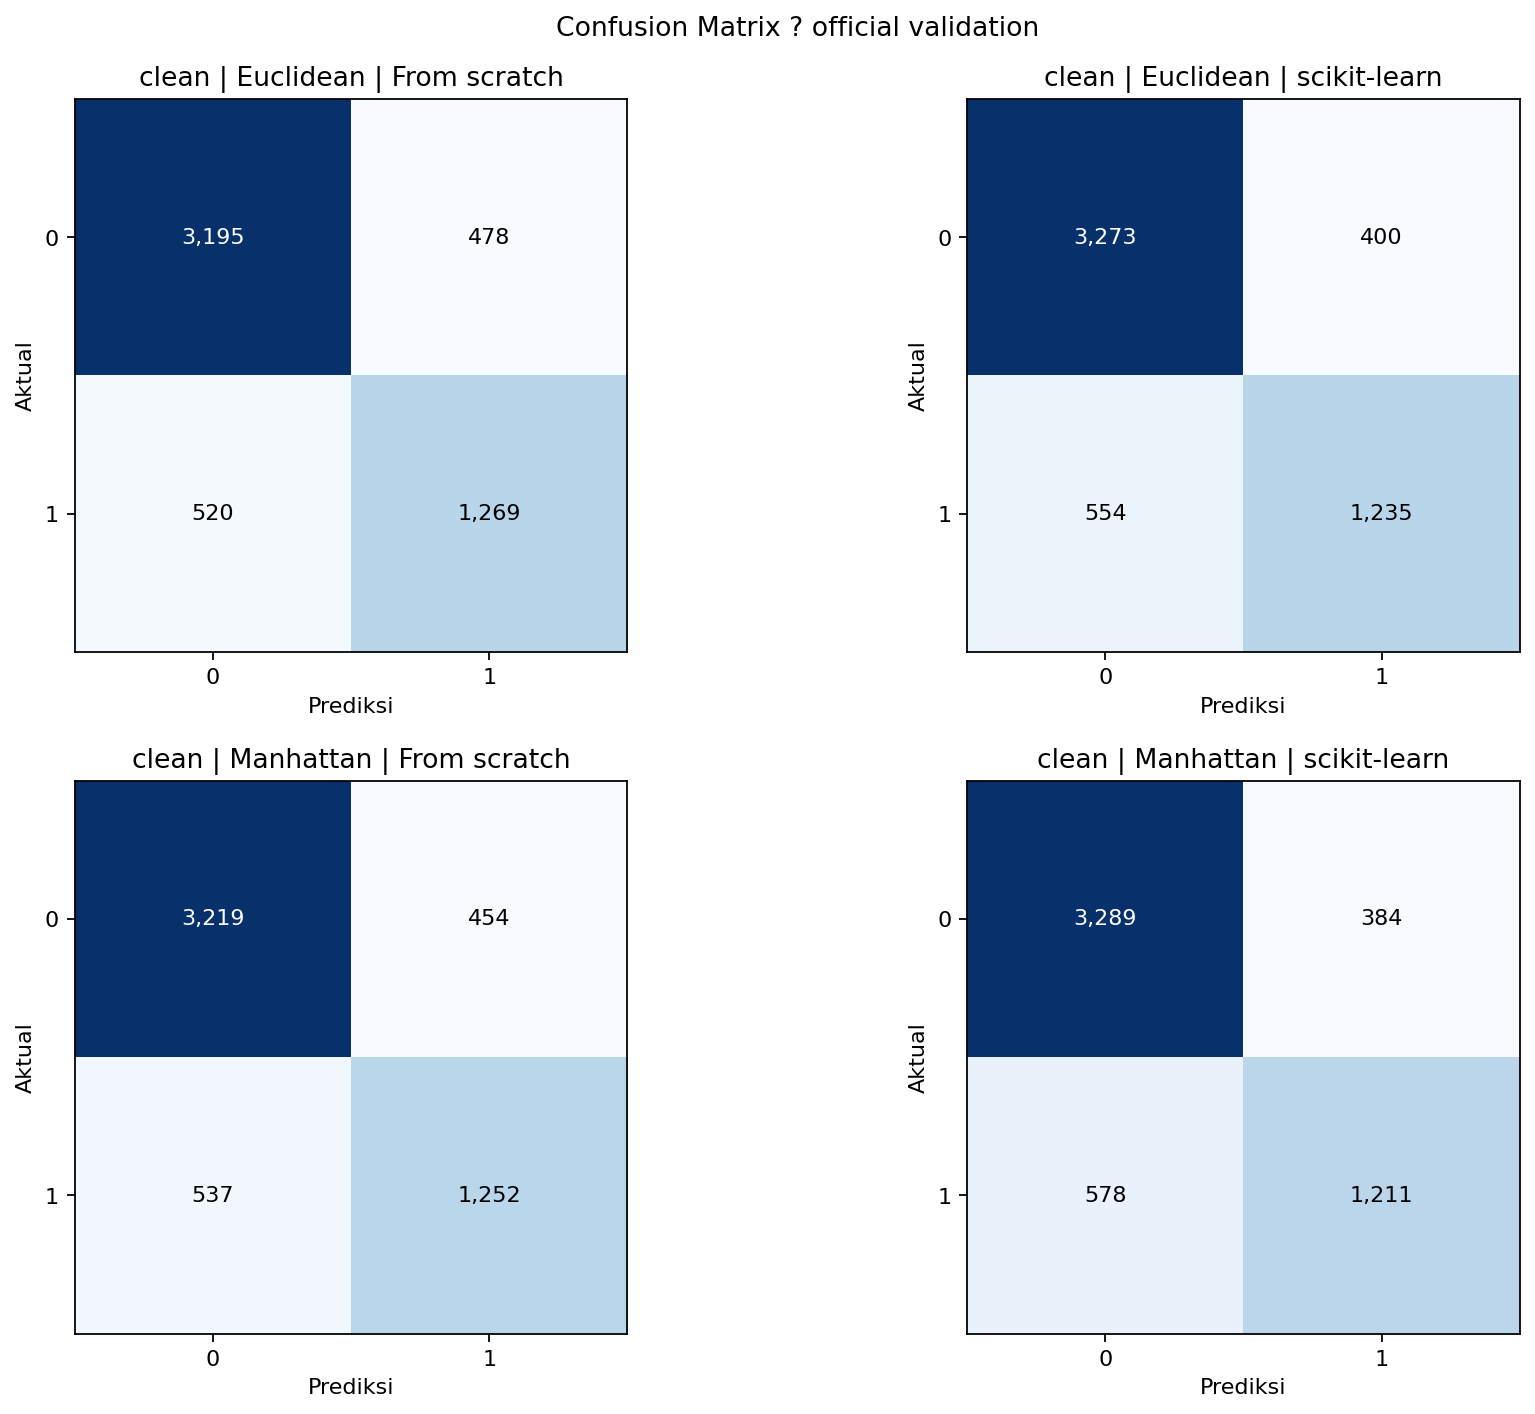

[Confusion Matrices Saved] ..\output\plots\knn_confusion_matrices.png
=== MCNEMAR (OFFICIAL VALIDATION; HOLM-CORRECTED) ===


,Contrast,Model A,Model B,"A correct, B wrong","A wrong, B correct",McNemar chi2,p-value,p-value (Holm),"Significant (Holm, 0.05)"
0,Scratch vs sklearn / Euclidean (best k),euclidean / From scratch,euclidean / scikit-learn,114,158,6.79779,0.00913,0.02738,True
1,Scratch vs sklearn / Manhattan (best k),manhattan / From scratch,manhattan / scikit-learn,141,170,2.52090,0.11235,0.22469,False
2,Scratch: best Euclidean vs best Manhattan,euclidean / From scratch,manhattan / From scratch,169,176,0.10435,0.74667,0.74667,False


[Scratch Model Bundle Saved/Load Verified] ..\output\models\knn_model.pkl | clean / euclidean / k=10
[Scratch Submission Saved] ..\output\submissions\submission_knn_clean.csv | clean / euclidean / k=10 | 6,844 rows
[Overall Scratch Winner] clean / euclidean / k=10 | ..\output\submissions\submission_knn_best.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [ ]:
from pathlib import Path
import pickle
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from src.preprocessing import DataPipeline
from src.utils import confusion_matrix

root_dir = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
root = Path(root_dir)
processed_dir = root / 'data' / 'processed'
raw_dir = root / 'data' / 'raw'
target_col, id_col = 'is_canceled', 'id'

# 1. Muat Dataset Resmi Hasil Pipeline Anggota 1 (train_dtl.csv + val_dtl.csv)
df_tr_cln = pd.read_csv(processed_dir / 'train_clean.csv', dtype={id_col: str})
df_va_cln = pd.read_csv(processed_dir / 'val_clean.csv', dtype={id_col: str})
df_raw_train = pd.read_csv(raw_dir / 'train.csv', dtype={id_col: str})
df_raw_lookup = df_raw_train.set_index(id_col, drop=False)
df_tr_raw = df_raw_lookup.loc[df_tr_cln[id_col]].reset_index(drop=True)
df_va_raw = df_raw_lookup.loc[df_va_cln[id_col]].reset_index(drop=True)
df_test_raw = pd.read_csv(raw_dir / 'test.csv', dtype={id_col: str})
assert df_tr_raw[id_col].equals(df_tr_cln[id_col])
assert df_va_raw[id_col].equals(df_va_cln[id_col])
assert np.array_equal(df_tr_raw[target_col], df_tr_cln[target_col])
assert np.array_equal(df_va_raw[target_col], df_va_cln[target_col])
feature_cols = [c for c in df_tr_cln.columns if c not in (id_col, target_col)]
assert feature_cols == [c for c in df_va_cln.columns if c not in (id_col, target_col)]

X_tr_knn = df_tr_cln[feature_cols].to_numpy(dtype=float)
y_tr_knn = df_tr_cln[target_col].to_numpy(dtype=int)
X_va_knn = df_va_cln[feature_cols].to_numpy(dtype=float)
y_va_knn = df_va_cln[target_col].to_numpy(dtype=int)

distance_metrics = ('euclidean', 'manhattan')
implementations = ('From scratch', 'scikit-learn')

# =============================================================================
# FASE 2 dan 3 menggunakan inner holdout supaya model tidak menjadi sgt optimis ketika evaluasi validation set
# =============================================================================

# 2. HYPERPARAMETER SEARCH 
idx_fit, idx_tune = train_test_split(
    np.arange(len(y_tr_knn)), test_size=0.2, random_state=RANDOM_SEED,
    stratify=y_tr_knn,
)
df_fit_raw = df_tr_raw.iloc[idx_fit].copy()
df_tune_raw = df_tr_raw.iloc[idx_tune].copy()
y_fit_knn, y_tune_knn = y_tr_knn[idx_fit], y_tr_knn[idx_tune]

inner_preprocessor = DataPipeline(use_pca=False, random_state=RANDOM_SEED).fit(df_fit_raw, y_fit_knn)
X_fit_knn = inner_preprocessor.transform(df_fit_raw, use_pca=False).to_numpy(dtype=float)
X_tune_knn = inner_preprocessor.transform(df_tune_raw, use_pca=False).to_numpy(dtype=float)

k_values = list(range(1, min(50, len(y_fit_knn)) + 1))
if not k_values:
    raise ValueError('Data train terlalu sedikit untuk pencarian k.')

# 3. TUNING DISTANCE + k 
def knn_grid_predictions(model, X, labels, candidate_ks, from_scratch, batch_size):
    predictions = {k: [] for k in candidate_ks}
    for start in range(0, len(X), batch_size):
        X_batch = X[start:start + batch_size]
        if from_scratch:
            distances = model._compute_distances(X_batch)
            nearest = np.argsort(distances, axis=1)[:, :max(candidate_ks)]
            neighbor_labels = model.y_train_[nearest]
        else:
            _, nearest = model.kneighbors(X_batch, n_neighbors=max(candidate_ks))
            neighbor_labels = labels[nearest]
        cumulative_positives = np.cumsum(neighbor_labels == 1, axis=1)
        for k in candidate_ks:
            prediction = cumulative_positives[:, k - 1] > k / 2
            predictions[k].append(prediction.astype(int))
    return {k: np.concatenate(parts) for k, parts in predictions.items()}


def knn_predict_batched(model, X, batch_size=16):
    return np.concatenate([model.predict(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])

tuning_rows = []
best_knn_by_config = {}
for metric in distance_metrics:
    for implementation in implementations:
        t0 = time.perf_counter()
        if implementation == 'From scratch':
            tuner = KNN(k=max(k_values), metric=metric).fit(X_fit_knn, y_fit_knn)
        else:
            tuner = KNeighborsClassifier(n_neighbors=max(k_values), metric=metric, n_jobs=-1).fit(X_fit_knn, y_fit_knn)
        grid_predictions = knn_grid_predictions(tuner, X_tune_knn, y_fit_knn, k_values,
                                                implementation == 'From scratch',
                                                16 if implementation == 'From scratch' else 256)
        elapsed = time.perf_counter() - t0
        for k in k_values:
            tuning_rows.append({
                'Distance': metric, 'Implementasi': implementation, 'k': k,
                'Tuning Macro F1': macro_f1_score(y_tune_knn, grid_predictions[k]),
                'Tuning time (s)': elapsed,
            })
df_knn_tuning = pd.DataFrame(tuning_rows)
for metric in distance_metrics:
    for implementation in implementations:
        rows = df_knn_tuning[(df_knn_tuning['Distance'] == metric) &
                             (df_knn_tuning['Implementasi'] == implementation)]
        best = rows.loc[rows['Tuning Macro F1'].idxmax()]
        best_knn_by_config[(metric, implementation)] = {
            'k': int(best['k']), 'macro_f1': float(best['Tuning Macro F1']),
        }
print('=== PENCARIAN k DAN DISTANCE ===')
display(df_knn_tuning.pivot_table(index='k', columns=['Distance', 'Implementasi'],
                                  values='Tuning Macro F1').round(4))
for (metric, implementation), best in best_knn_by_config.items():
    print('{} / {}: k={} | Macro F1={:.4f}'.format(metric, implementation, best['k'], best['macro_f1']))

# 4. EVALUASI PADA VALIDATION (train_clean.csv / val_clean.csv)
comparison_rows, val_preds_store, val_models_store = [], {}, {}
for metric in distance_metrics:
    for implementation in implementations:
        config = (metric, implementation)
        best = best_knn_by_config[config]
        if implementation == 'From scratch':
            model = KNN(k=best['k'], metric=metric).fit(X_tr_knn, y_tr_knn)
        else:
            model = KNeighborsClassifier(n_neighbors=best['k'], metric=metric, n_jobs=-1).fit(X_tr_knn, y_tr_knn)
        val_models_store[config] = model
        t0 = time.perf_counter()
        y_pred_knn = knn_predict_batched(model, X_va_knn)
        predict_seconds = time.perf_counter() - t0
        val_preds_store[config] = y_pred_knn
        tn, fp, fn, tp = confusion_matrix(y_va_knn, y_pred_knn)
        comparison_rows.append({
            'Distance': metric, 'Implementasi': implementation, 'k terbaik': best['k'],
            'Tuning Macro F1': best['macro_f1'], 'Accuracy': accuracy_score(y_va_knn, y_pred_knn),
            'Precision': precision_score(y_va_knn, y_pred_knn), 'Recall': recall_score(y_va_knn, y_pred_knn),
            'Macro F1': macro_f1_score(y_va_knn, y_pred_knn),
            'Cost (2FP+FN)': calculate_custom_cost(y_va_knn, y_pred_knn),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp, 'Val predict time (s)': predict_seconds,
        })
df_knn_comparison = pd.DataFrame(comparison_rows)
print('=== VALIDATION METRICS + CONFUSION MATRIX COUNTS ===')
display(df_knn_comparison.round(4))

# 5. PLOT TUNING PER DISTANCE DAN IMPLEMENTASI
plot_configs = [(metric, implementation) for metric in distance_metrics for implementation in implementations]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, config in zip(axes.flat, plot_configs):
    metric, implementation = config
    df_plot = df_knn_tuning[(df_knn_tuning['Distance'] == metric) &
                            (df_knn_tuning['Implementasi'] == implementation)]
    ax.plot(df_plot['k'], df_plot['Tuning Macro F1'], marker='o', color='#4472C4')
    ax.axvline(best_knn_by_config[config]['k'], color='#D62728', linestyle='--', alpha=0.7)
    ax.set(title='clean | {} | {}'.format(metric.title(), implementation), xlabel='k', ylabel='Macro F1')
    ax.set_xticks([1, 10, 20, 30, 40, 50])
    ax.grid(alpha=0.3)
fig.suptitle('KNN Hyperparameter Observation ? clean, inner holdout')
fig.tight_layout()
knn_plot_path = root / 'output' / 'plots' / 'knn_k_search.png'
knn_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(knn_plot_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(knn_plot_path)))
print('[Tuning Plot Saved] {}'.format(knn_plot_path))

# 6. CONFUSION MATRIX PADA VALIDATION
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, config in zip(axes.flat, plot_configs):
    metric, implementation = config
    tn, fp, fn, tp = confusion_matrix(y_va_knn, val_preds_store[config])
    cm = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm, cmap='Blues')
    for row in range(2):
        for col in range(2):
            color = 'white' if cm[row, col] > cm.max() / 2 else 'black'
            ax.text(col, row, '{:,}'.format(cm[row, col]), ha='center', va='center', color=color)
    ax.set(title='clean | {} | {}'.format(metric.title(), implementation), xlabel='Prediksi', ylabel='Aktual', xticks=[0, 1], yticks=[0, 1])
fig.suptitle('Confusion Matrix ? official validation')
fig.tight_layout()
knn_confusion_path = root / 'output' / 'plots' / 'knn_confusion_matrices.png'
knn_confusion_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(knn_confusion_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(knn_confusion_path)))
print('[Confusion Matrices Saved] {}'.format(knn_confusion_path))

# 8. REFIT ON TRAIN + VALIDATION, SAVE MODEL, SUBMISSION
best_scratch_config = max(
    [config for config in best_knn_by_config if config[1] == 'From scratch'],
    key=lambda config: best_knn_by_config[config]['macro_f1'],
)
best_knn_metric, _ = best_scratch_config
best_knn_k = best_knn_by_config[best_scratch_config]['k']
df_all_raw = pd.concat([df_tr_raw, df_va_raw], ignore_index=True)
y_all_knn = df_all_raw[target_col].to_numpy(dtype=int)
final_preprocessor = DataPipeline(use_pca=False, random_state=RANDOM_SEED).fit(df_all_raw, y_all_knn)
X_all_knn = final_preprocessor.transform(df_all_raw, use_pca=False).to_numpy(dtype=float)
X_test_knn = final_preprocessor.transform(df_test_raw, use_pca=False).to_numpy(dtype=float)
best_knn_model = KNN(k=best_knn_k, metric=best_knn_metric).fit(X_all_knn, y_all_knn)
model_bundle = {
    'preprocessor': final_preprocessor, 'model': best_knn_model, 'best_representation': 'clean',
    'best_configuration': {'representation': 'clean', 'distance': best_knn_metric, 'k': best_knn_k},
    'tuning_macro_f1': best_knn_by_config[best_scratch_config]['macro_f1'],
}
model_out_path = root / 'output' / 'models' / 'knn_model.pkl'
model_out_path.parent.mkdir(parents=True, exist_ok=True)
with model_out_path.open('wb') as model_file:
    pickle.dump(model_bundle, model_file)
with model_out_path.open('rb') as model_file:
    loaded_model_bundle = pickle.load(model_file)
X_test_check = loaded_model_bundle['preprocessor'].transform(df_test_raw.iloc[:64], use_pca=False).to_numpy(dtype=float)
assert np.array_equal(knn_predict_batched(best_knn_model, X_test_knn[:64]),
                      knn_predict_batched(loaded_model_bundle['model'], X_test_check)), 'Prediksi berubah setelah save/load.'
print('[Scratch Model Bundle Saved/Load Verified] {} | clean / {} / k={}'.format(model_out_path, best_knn_metric, best_knn_k))

df_sample_sub = pd.read_csv(raw_dir / 'sample_submission.csv', dtype={id_col: str})
y_test_pred_knn = knn_predict_batched(best_knn_model, X_test_knn)
df_submission_knn = pd.DataFrame({id_col: df_test_raw[id_col].astype(str), target_col: y_test_pred_knn.astype(int)})
assert df_submission_knn.shape == df_sample_sub.shape
assert list(df_submission_knn.columns) == list(df_sample_sub.columns)
assert df_submission_knn[id_col].equals(df_sample_sub[id_col])
assert df_submission_knn[target_col].notna().all()
assert set(df_submission_knn[target_col].unique()).issubset({0, 1})
submission_path = root / 'output' / 'submissions' / 'submission_knn.csv'
submission_path.parent.mkdir(parents=True, exist_ok=True)
df_submission_knn.to_csv(submission_path, index=False)
print('[Overall Winner] clean / {} / k={} | {}'.format(best_knn_metric, best_knn_k, submission_path))
display(df_submission_knn.head())


## 2. Decision Tree Learning (DTL — Varian Pilihan: C4.5) — Anggota 2 (`13524053`)

Sesuai Cakupan Poin 2 spesifikasi (*"Pilih salah satu algoritma DTL: ID3, C4.5, atau CART"*), kelompok memilih **C4.5** sebagai varian utama DTL *from scratch* pada `src/dtl.py` (100% pure NumPy, bebas `sklearn`, dan tetap berupa **1 pohon keputusan tunggal / non-ensemble**):
1. **Spesifikasi Wajib (C4.5)**: Menggunakan *Gain Ratio* dengan heuristik *above-average gain* [2], penanganan fitur numerik kontinu (*midpoint threshold*), kategorikal *multi-way*, penanganan *missing values* (`NaN`) berbobot pecahan ala Quinlan [2], *save/load*, serta komparasi terhadap `sklearn.tree.DecisionTreeClassifier(criterion='entropy', ccp_alpha=...)` pada **dataset penginapan resmi hasil pipeline Anggota 1** (`train_dtl.csv` / `val_dtl.csv` vs `train_clean.csv` / `val_clean.csv`).
2. **Bonus Visualisasi Tree (+1 Poin)**: Fungsi `export_tree_visualization(model, top_n=3, ...)` yang menggambar struktur percabangan pohon dari *root* hingga kedalaman `top_n` ke `output/plots/dtl_tree_top_n.png`.
3. **Bonus Optimasi Model DTL (+2 Poin — Di Luar Salindia Materi 10a/10c)**:
   - **Opsi A — Particle Swarm Optimization (PSO)** (*Kennedy & Eberhart, 1995 [7]; Shi & Eberhart, 1998 [8]*): Mengoptimasi struktur & *hyperparameter* C4.5 (`max_depth`, `min_samples_leaf`, `min_samples_split`, `log10(ccp_alpha)`) secara deterministik terhadap *fitness* **Macro F1** validasi internal di dalam `train_dtl` (bebas *leakage* terhadap `val_dtl`), lalu menghasilkan **1 model C4.5 tunggal terbaik**.
   - **Opsi B — Histogram-Based Quantile Split Optimization** (*Ke et al., 2017 [5]; Chen & Guestrin, 2016 [6]*) + **Minimal Cost-Complexity Weakest-Link Pruning Path** (*Breiman et al., 1984 [4], Bab 3*): Pra-diskretisasi kuantil $B=64$ *bins* (bebas *leakage*, $O(B)$ per simpul) + pemangkasan *weakest-link* berbasis *weighted impurity* $R_\alpha(T) = R(T) + \alpha|L(T)|$ tanpa membuang data latih seperti REP (Materi 10c).
   - **Opsi C — Surrogate Splits** (*Breiman et al., 1984 [4], Bab 5.3*): Diuji pada studi ablasi sebagai pembanding penanganan `NaN` berbasis asosiasi prediktif $\lambda(s^* \mid s') > 0$.

**Referensi Ilmiah (Format IEEE):**
- `[1]` J. R. Quinlan, "Induction of decision trees," *Machine Learning*, vol. 1, no. 1, pp. 81–106, 1986.
- `[2]` J. R. Quinlan, *C4.5: Programs for Machine Learning*. San Mateo, CA, USA: Morgan Kaufmann, 1993.
- `[3]` T. M. Mitchell, *Machine Learning*. New York, NY, USA: McGraw-Hill, 1997, ch. 3.
- `[4]` L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Wadsworth, 1984, ch. 3 & ch. 5.
- `[5]` G. Ke *et al.*, "LightGBM: A highly efficient gradient boosting decision tree," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 30, 2017, pp. 3146–3154.
- `[6]` T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining (KDD)*, 2016, pp. 785–794.
- `[7]` J. Kennedy and R. Eberhart, "Particle swarm optimization," in *Proc. IEEE Int. Conf. Neural Networks (ICNN)*, vol. 4, 1995, pp. 1942–1948.
- `[8]` Y. Shi and R. Eberhart, "A modified particle swarm optimizer," in *Proc. IEEE Int. Conf. Evolutionary Computation (ICEC)*, 1998, pp. 69–73.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import chi2
from src.dtl import DecisionTree, PSODecisionTreeOptimizer, export_tree_visualization
from src.utils import confusion_matrix

root_dir = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
train_dtl_path = os.path.join(root_dir, 'data', 'processed', 'train_dtl.csv')
val_dtl_path = os.path.join(root_dir, 'data', 'processed', 'val_dtl.csv')
train_clean_path = os.path.join(root_dir, 'data', 'processed', 'train_clean.csv')
val_clean_path = os.path.join(root_dir, 'data', 'processed', 'val_clean.csv')
raw_train_path = os.path.join(root_dir, 'data', 'raw', 'train.csv')

def macro_f1_score(y_true, y_pred):
    return 0.5 * (f1_score(y_true, y_pred) + f1_score(1 - y_true, 1 - y_pred))

def mcnemar_test(y_true, pred_a, pred_b):
    """Uji signifikansi McNemar (Materi 13) dengan koreksi kontinuitas Edwards (df=1)."""
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    stat = ((abs(b - c) - 1.0) ** 2) / (b + c) if (b + c) > 0 else 0.0
    p_val = float(1.0 - chi2.cdf(stat, df=1)) if (b + c) > 0 else 1.0
    return b, c, stat, p_val

# 1. Muat Dataset Resmi Hasil Pipeline Anggota 1 (train_dtl.csv + val_dtl.csv)
has_official_split = all(os.path.exists(p) for p in (train_dtl_path, val_dtl_path, train_clean_path, val_clean_path))
if has_official_split:
    df_tr_dtl = pd.read_csv(train_dtl_path, dtype={'id': str})
    df_va_dtl = pd.read_csv(val_dtl_path, dtype={'id': str})
    df_tr_cln = pd.read_csv(train_clean_path, dtype={'id': str})
    df_va_cln = pd.read_csv(val_clean_path, dtype={'id': str})
    assert (df_tr_dtl['id'] == df_tr_cln['id']).all(), 'ID train_dtl != train_clean!'
    assert (df_va_dtl['id'] == df_va_cln['id']).all(), 'ID val_dtl != val_clean!'
    src_label = 'data/processed/train_dtl.csv + val_dtl.csv (Pipeline Resmi Anggota 1)'
elif os.path.exists(raw_train_path):
    df_full = pd.read_csv(raw_train_path, dtype={'id': str})
    n_val = int(0.2 * len(df_full))
    df_tr_dtl, df_va_dtl = df_full.iloc[:-n_val].copy(), df_full.iloc[-n_val:].copy()
    df_tr_cln, df_va_cln = None, None
    src_label = raw_train_path
else:
    X_syn, y_syn = generate_dtl_synthetic_data(n_samples=600, random_state=RANDOM_SEED)
    df_full = pd.DataFrame(X_syn, columns=['lead_time', 'adr_price', 'market_segment', 'deposit_type'])
    df_full['is_canceled'] = y_syn
    df_tr_dtl, df_va_dtl = df_full.iloc[:480].copy(), df_full.iloc[480:].copy()
    df_tr_cln, df_va_cln = None, None
    src_label = 'synthetic_fallback'

target_col = 'is_canceled' if 'is_canceled' in df_tr_dtl.columns else df_tr_dtl.columns[-1]
dtl_feat_names = [c for c in df_tr_dtl.columns if c not in ('id', target_col)]
cat_col_names = {'meal_package', 'room_category', 'booking_channel', 'market_segment', 'deposit_type'}
dtl_cat_indices = [i for i, c in enumerate(dtl_feat_names) if c in cat_col_names or df_tr_dtl[c].dtype == object or str(df_tr_dtl[c].dtype) in ('str', 'string')]

X_tr_dtl = df_tr_dtl[dtl_feat_names].to_numpy(dtype=object)
y_tr_dtl = df_tr_dtl[target_col].to_numpy(dtype=int)
X_va_dtl = df_va_dtl[dtl_feat_names].to_numpy(dtype=object)
y_va_dtl = df_va_dtl[target_col].to_numpy(dtype=int)

base_cols = dtl_feat_names[:17] if len(dtl_feat_names) >= 17 else dtl_feat_names
has_nan_base = df_va_dtl[base_cols].isna().any(axis=1).to_numpy()

print(f"[DTL-C4.5] Sumber data : {src_label}")
print(f"[DTL-C4.5] Train shape : {X_tr_dtl.shape} | Val shape: {X_va_dtl.shape}")
print(f"[DTL-C4.5] Fitur kat.  : {[dtl_feat_names[i] for i in dtl_cat_indices]}")

# =============================================================================
# EKSPERIMEN 1: ABLATION STUDY BONUS 6 PADA VARIAN C4.5 (Baseline Kuliah vs Opsi A, B, C)
# =============================================================================
c45_ablation = [
    ('Baseline Kuliah: C4.5 Exact (Unpruned)', lambda: DecisionTree(criterion='c45', split_strategy='exact', missing_strategy='fractional', max_depth=18, min_samples_leaf=5, use_pruning=False, categorical_features=dtl_cat_indices, random_state=RANDOM_SEED)),
    ('Baseline Kuliah: C4.5 Exact + REP (Materi 10c)', lambda: DecisionTree(criterion='c45', split_strategy='exact', missing_strategy='fractional', max_depth=18, min_samples_leaf=5, use_pruning=True, pruning_method='rep', val_split_ratio=0.15, categorical_features=dtl_cat_indices, random_state=RANDOM_SEED)),
    ('Opsi B: C4.5 Hist(B=64) + Minimal CCP', lambda: DecisionTree(criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='fractional', max_depth=18, min_samples_leaf=5, use_pruning=True, pruning_method='ccp', ccp_alpha=0.0003, categorical_features=dtl_cat_indices, random_state=RANDOM_SEED)),
    ('Opsi C: C4.5 Hist(B=64) + Surrogate Splits + CCP', lambda: DecisionTree(criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='surrogate', max_surrogates=3, max_depth=18, min_samples_leaf=5, use_pruning=True, pruning_method='ccp', ccp_alpha=0.0003, categorical_features=dtl_cat_indices, random_state=RANDOM_SEED)),
    ('Opsi A1 (Pemenang): PSO + C4.5 Hist(B=64) + CCP', lambda: PSODecisionTreeOptimizer(criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='fractional', n_particles=8, n_iters=4, categorical_features=dtl_cat_indices, random_state=RANDOM_SEED)),
]

ablation_rows = []
val_preds_store = {}
pso_winner_opt = None
for label, builder in c45_ablation:
    t0 = time.perf_counter()
    clf = builder()
    clf.fit(X_tr_dtl, y_tr_dtl)
    elapsed = time.perf_counter() - t0
    preds = clf.predict(X_va_dtl)
    val_preds_store[label] = preds
    tree_obj = clf.best_model_ if isinstance(clf, PSODecisionTreeOptimizer) else clf
    if isinstance(clf, PSODecisionTreeOptimizer):
        pso_winner_opt = clf
    ablation_rows.append({
        'Konfigurasi C4.5 (Holdout val_dtl)': label,
        'Val Macro F1': macro_f1_score(y_va_dtl, preds),
        'Macro F1 (NaN)': macro_f1_score(y_va_dtl[has_nan_base], preds[has_nan_base]) if np.any(has_nan_base) else np.nan,
        'Macro F1 (Full)': macro_f1_score(y_va_dtl[~has_nan_base], preds[~has_nan_base]) if np.any(~has_nan_base) else np.nan,
        'Accuracy': accuracy_score(y_va_dtl, preds),
        'Precision': precision_score(y_va_dtl, preds),
        'Recall': recall_score(y_va_dtl, preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, preds),
        'Nodes': tree_obj.get_n_nodes(),
        'Depth': tree_obj.get_depth(),
        'Time (s)': elapsed,
    })

df_c45_ablation = pd.DataFrame(ablation_rows)
print("\n=== TABEL 1: ABLATION STUDY BONUS 6 — VARIAN C4.5 (BASELINE KULIAH VS OPSI A, B, C) ===")
display(df_c45_ablation.round(4))

print(f"[PSO Best Params] {pso_winner_opt.best_params_} | Inner Fitness: {pso_winner_opt.best_score_:.5f}")
print(f"[PSO Convergence] {[(h['iter'], round(h['g_best_macro_f1'], 5)) for h in pso_winner_opt.history_]}")

b_mc, c_mc, stat_mc, p_mc = mcnemar_test(
    y_va_dtl,
    val_preds_store['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)'],
    val_preds_store['Opsi A1 (Pemenang): PSO + C4.5 Hist(B=64) + CCP'],
)
print(f"[McNemar Test — Baseline REP vs Opsi A1 PSO+Hist+CCP] b={b_mc}, c={c_mc}, chi2={stat_mc:.4f}, p-value={p_mc:.6f}")

# =============================================================================
# EKSPERIMEN 2: KOMPARASI HEAD-TO-HEAD C4.5 FROM SCRATCH VS SCIKIT-LEARN (SPEK HAL. 10)
# =============================================================================
if has_official_split:
    cln_feat_names = [c for c in df_tr_cln.columns if c not in ('id', target_col)]
    X_tr_sk = df_tr_cln[cln_feat_names].to_numpy(dtype=float)
    X_va_sk = df_va_cln[cln_feat_names].to_numpy(dtype=float)
else:
    X_tr_sk = np.nan_to_num(pd.DataFrame(X_tr_dtl).apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float), nan=0.0)
    X_va_sk = np.nan_to_num(pd.DataFrame(X_va_dtl).apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float), nan=0.0)

best_c45_model = pso_winner_opt.best_model_
best_c45_model.feature_names_ = dtl_feat_names
best_c45_preds = val_preds_store['Opsi A1 (Pemenang): PSO + C4.5 Hist(B=64) + CCP']

comp_rows = [
    {
        'Komparasi C4.5 (Holdout Resmi 5,462 baris)': 'Scratch C4.5 Baseline Kuliah (Exact + REP)',
        'Val Macro F1': macro_f1_score(y_va_dtl, val_preds_store['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)']),
        'Accuracy': accuracy_score(y_va_dtl, val_preds_store['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)']),
        'Precision': precision_score(y_va_dtl, val_preds_store['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)']),
        'Recall': recall_score(y_va_dtl, val_preds_store['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)']),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, val_preds_store['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)']),
        'Nodes': int(df_c45_ablation.loc[1, 'Nodes']),
        'Depth': int(df_c45_ablation.loc[1, 'Depth']),
    },
    {
        'Komparasi C4.5 (Holdout Resmi 5,462 baris)': 'Scratch C4.5 Pemenang (PSO + Hist B=64 + CCP)',
        'Val Macro F1': macro_f1_score(y_va_dtl, best_c45_preds),
        'Accuracy': accuracy_score(y_va_dtl, best_c45_preds),
        'Precision': precision_score(y_va_dtl, best_c45_preds),
        'Recall': recall_score(y_va_dtl, best_c45_preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, best_c45_preds),
        'Nodes': best_c45_model.get_n_nodes(),
        'Depth': best_c45_model.get_depth(),
    },
]

for alpha_sk in (round(pso_winner_opt.best_params_['ccp_alpha'], 6), 0.01):
    sk_c45 = DecisionTreeClassifier(criterion='entropy', ccp_alpha=alpha_sk, random_state=RANDOM_SEED)
    sk_c45.fit(X_tr_sk, y_tr_dtl)
    sk_preds = sk_c45.predict(X_va_sk)
    comp_rows.append({
        'Komparasi C4.5 (Holdout Resmi 5,462 baris)': f"Sklearn C4.5 (criterion='entropy', ccp_alpha={alpha_sk})",
        'Val Macro F1': macro_f1_score(y_va_dtl, sk_preds),
        'Accuracy': accuracy_score(y_va_dtl, sk_preds),
        'Precision': precision_score(y_va_dtl, sk_preds),
        'Recall': recall_score(y_va_dtl, sk_preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, sk_preds),
        'Nodes': sk_c45.tree_.node_count,
        'Depth': sk_c45.get_depth(),
    })

df_c45_comp = pd.DataFrame(comp_rows)
print("\n=== TABEL 2: KOMPARASI C4.5 FROM SCRATCH (val_dtl) VS SCIKIT-LEARN (val_clean) ===")
display(df_c45_comp.round(4))

# =============================================================================
# EKSPERIMEN 3: VERIFIKASI STABILITAS 5-FOLD CV & ANTI-OVERFITTING MODEL PEMENANG
# =============================================================================
bp = pso_winner_opt.best_params_
cv_tr_f1, cv_va_f1 = [], []
for tr_idx, va_idx in k_fold_split(X_tr_dtl, y_tr_dtl, k=5, seed=RANDOM_SEED):
    m_cv = DecisionTree(
        criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='fractional',
        max_depth=bp['max_depth'], min_samples_leaf=bp['min_samples_leaf'],
        min_samples_split=bp['min_samples_split'], use_pruning=True, pruning_method='ccp',
        ccp_alpha=bp['ccp_alpha'], categorical_features=dtl_cat_indices, random_state=RANDOM_SEED,
    )
    m_cv.fit(X_tr_dtl[tr_idx], y_tr_dtl[tr_idx])
    cv_tr_f1.append(macro_f1_score(y_tr_dtl[tr_idx], m_cv.predict(X_tr_dtl[tr_idx])))
    cv_va_f1.append(macro_f1_score(y_tr_dtl[va_idx], m_cv.predict(X_tr_dtl[va_idx])))
print(f"\n[5-Fold CV Stabilitas Pemenang Opsi A1] Train Macro F1: {np.mean(cv_tr_f1):.4f} ± {np.std(cv_tr_f1):.4f} | Val Macro F1: {np.mean(cv_va_f1):.4f} ± {np.std(cv_va_f1):.4f} | Gap: {np.mean(cv_tr_f1)-np.mean(cv_va_f1):.4f}")

# =============================================================================
# EKSPERIMEN 4: SAVE/LOAD VERIFICATION, VISUALISASI TOP-3 (+1 POIN), & ERROR ANALYSIS
# =============================================================================
model_out_path = os.path.join(root_dir, 'output', 'models', 'dtl_model.pkl')
plot_out_path = os.path.join(root_dir, 'output', 'plots', 'dtl_tree_top_n.png')
best_c45_model.save(model_out_path)
loaded_dtl_model = DecisionTree.load(model_out_path)

assert np.allclose(best_c45_model.predict_proba(X_va_dtl), loaded_dtl_model.predict_proba(X_va_dtl))
assert np.array_equal(best_c45_preds, loaded_dtl_model.predict(X_va_dtl))
print(f"[Save/Load Verified] Prediksi & probabilitas 100% identik pada {len(X_va_dtl):,} baris val_dtl.")

export_tree_visualization(loaded_dtl_model, top_n=3, feature_names=dtl_feat_names, output_path=plot_out_path)

tn, fp, fn, tp = confusion_matrix(y_va_dtl, best_c45_preds)
print(f"\n=== ERROR ANALYSIS MODEL C4.5 PEMENANG (val_dtl: {len(X_va_dtl):,} BARIS) ===")
print(f"Confusion Matrix : TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}")
print(f"Val Macro F1     : {macro_f1_score(y_va_dtl, best_c45_preds):.4f} | Accuracy: {accuracy_score(y_va_dtl, best_c45_preds):.4f} | Cost: {calculate_custom_cost(y_va_dtl, best_c45_preds):.0f}")
print(f"  -> Baris mengandung NaN ({has_nan_base.sum():,} baris): Macro F1 = {macro_f1_score(y_va_dtl[has_nan_base], best_c45_preds[has_nan_base]):.4f}")
print(f"  -> Baris lengkap tanpa NaN ({(~has_nan_base).sum():,} baris): Macro F1 = {macro_f1_score(y_va_dtl[~has_nan_base], best_c45_preds[~has_nan_base]):.4f}")

df_imp = pd.DataFrame({'Feature': dtl_feat_names, 'Importance': loaded_dtl_model.feature_importances_}).sort_values('Importance', ascending=False)
print("\nTop-10 Fitur Paling Berpengaruh (Feature Importances C4.5):")
display(df_imp.head(10).round(4))

## 3. Logistic Regression — Anggota 3 (13524060)

Komparasi ini memakai konfigurasi terpilih dari [tuning pada notebook terintegrasi](Copy_of_Notebook_Template_Tugas_Besar_2_IF3170_Inteligensi_Artifisial_2026_2027.ipynb#logistic-regression), yaitu Elastic Net dengan `C=1`, `l1_ratio=0.5`, dan ambang 0,45. Jalankan sel LR di bawah untuk melatih satu model FISTA NumPy dan satu model scikit-learn SAGA. Pencarian hiperparameter tetap berada di notebook terintegrasi.

Split resmi dibentuk dari `train.csv` dengan deduplikasi berdasarkan fitur dan target, lalu validasi stratified 20% dengan seed 42. Satu `BookingFeatureTransformer` di-fit pada partisi latih dan menghasilkan 72 fitur tanpa PCA untuk kedua model. Kekuatan penalti FISTA adalah $\lambda=1/(n_{\mathrm{latih}}C)$ agar setara dengan objektif rata-rata scikit-learn. Kedua model memakai ambang yang sama pada probabilitas kelas pembatalan.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import f1_score as sklearn_f1_score
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

lr_root = Path.cwd()
if lr_root.name == "notebooks":
    lr_root = lr_root.parent
if str(lr_root) not in sys.path:
    sys.path.insert(0, str(lr_root))

from src.logistic_regression import BookingFeatureTransformer, LogisticRegression
from src.utils import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

lr_raw = pd.read_csv(lr_root / "data" / "raw" / "train.csv", dtype={"id": str})
lr_raw = lr_raw.drop_duplicates(subset=lr_raw.columns.drop("id"), keep="first")
lr_train, lr_validation = train_test_split(
    lr_raw, test_size=0.2, random_state=42, stratify=lr_raw["is_canceled"],
)
lr_transformer = BookingFeatureTransformer().fit(lr_train)
lr_X_train = lr_transformer.transform(lr_train).to_numpy(dtype=float)
lr_X_val = lr_transformer.transform(lr_validation).to_numpy(dtype=float)
lr_y_train = lr_train["is_canceled"].to_numpy(dtype=int)
lr_y_val = lr_validation["is_canceled"].to_numpy(dtype=int)

# Konfigurasi terpilih dari inner holdout pada notebook terintegrasi.
lr_C, lr_ratio, lr_threshold = 1.0, 0.5, 0.45
lr_scratch = LogisticRegression(
    penalty="elasticnet", reg_lambda=1 / (len(lr_y_train) * lr_C),
    l1_ratio=lr_ratio, n_iters=1500, tol=1e-5,
)
lr_saga = SklearnLogisticRegression(
    solver="saga", penalty="elasticnet", C=lr_C, l1_ratio=lr_ratio,
    max_iter=10000, tol=1e-5, random_state=42,
)

lr_rows, lr_predictions = [], []
for lr_name, lr_model in (("FISTA (scratch)", lr_scratch), ("SAGA (scikit-learn)", lr_saga)):
    with threadpool_limits(limits=1, user_api="blas"):
        lr_start = perf_counter()
        lr_model.fit(lr_X_train, lr_y_train)
        lr_fit_seconds = perf_counter() - lr_start
        lr_start = perf_counter()
        lr_proba = lr_model.predict_proba(lr_X_val)[:, 1]
        lr_predict_seconds = perf_counter() - lr_start

    lr_pred = (lr_proba >= lr_threshold).astype(int)
    lr_predictions.append(lr_pred)
    lr_tn, lr_fp, lr_fn, lr_tp = confusion_matrix(lr_y_val, lr_pred)
    lr_rows.append({
        "Model": lr_name, "Ambang": lr_threshold,
        "Macro F1": sklearn_f1_score(lr_y_val, lr_pred, average="macro"),
        "F1 positif": f1_score(lr_y_val, lr_pred),
        "Akurasi": accuracy_score(lr_y_val, lr_pred),
        "Presisi": precision_score(lr_y_val, lr_pred),
        "Recall": recall_score(lr_y_val, lr_pred),
        "TN": lr_tn, "FP": lr_fp, "FN": lr_fn, "TP": lr_tp,
        "Latih (s)": lr_fit_seconds, "Probabilitas validasi (s)": lr_predict_seconds,
    })

lr_comparison = pd.DataFrame(lr_rows)
print(f"Latih: {lr_X_train.shape} | Validasi: {lr_X_val.shape}")
display(lr_comparison.round(6))
print(f"Label validasi berbeda: {np.count_nonzero(lr_predictions[0] != lr_predictions[1]):,}")
print(
    f"FISTA: {lr_scratch.n_iter_} pembaruan, residu KKT {lr_scratch.optimality_:.2e}, "
    f"konvergen: {lr_scratch.converged_}. SAGA: {lr_saga.n_iter_[0]} epoch, "
    f"batas iterasi tercapai: {lr_saga.n_iter_[0] >= lr_saga.max_iter}."
)

Latih: (21847, 72) | Validasi: (5462, 72)


,Model,Ambang,Macro F1,F1 positif,Akurasi,Presisi,Recall,TN,FP,FN,TP,Latih (s),Probabilitas validasi (s)
0,FISTA (scratch),0.45,0.772218,0.688979,0.802636,0.711986,0.667412,3190,483,595,1194,1.065486,0.000373
1,SAGA (scikit-learn),0.45,0.772218,0.688979,0.802636,0.711986,0.667412,3190,483,595,1194,42.055984,0.001201


Label validasi berbeda: 0
FISTA: 585 pembaruan, residu KKT 9.98e-06, konvergen: True. SAGA: 3121 epoch, batas iterasi tercapai: False.


### Interpretasi

Pada split ini, FISTA dan SAGA menghasilkan label validasi yang sama pada ambang terpilih. Macro F1 memberi bobot yang sama pada kedua kelas. F1 positif, presisi, dan recall menilai khusus kelas pembatalan. Waktu dihitung di luar prapemrosesan dengan satu thread BLAS. Jumlah pembaruan FISTA dan epoch SAGA mengikuti kriteria henti masing-masing solver.

Rujukan metode. [Beck dan Teboulle (2009), FISTA dan backtracking](https://doi.org/10.1137/080716542) · [Objektif biner scikit-learn](https://scikit-learn.org/1.6/modules/linear_model.html#binary-case) · [Defazio, Bach, dan Lacoste-Julien (2014), SAGA](https://arxiv.org/abs/1407.0202)

## 4. Support Vector Machine (SVM) — Anggota 4
Komparasi `src.svm.SVM` (Linear, Polynomial, Gaussian RBF) vs `sklearn.svm.SVC` & Plot Bidang Pemisah 2D

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# 1. Split data sintetis (atau ganti dengan load data bersih dari data/processed/ bila perlu)
X_tr_svm, X_va_svm, y_tr_svm, y_va_svm = train_test_split(
    X_dummy,
    y_dummy,
    test_size=0.2,
    stratify=y_dummy,
    random_state=RANDOM_SEED,
)

kernels = ["linear", "poly", "rbf"]
results = []

for kernel_name in kernels:
    # --- From-scratch SVM (cvxopt) ---
    t0 = time.perf_counter()
    scratch_svm = SVM(
        C=1.0,
        kernel=kernel_name,
        gamma="scale" if kernel_name != "linear" else None,
        random_state=RANDOM_SEED,
    )
    # Catatan: di SVM from-scratch, jika gamma=None maka dipakai 1/n_features;
    # set gamma=1.0 / X_tr_svm.shape[1] agar setara dengan 'scale'/standar
    scratch_svm = SVM(
        C=1.0,
        kernel=kernel_name,
        gamma=1.0 / X_tr_svm.shape[1],
        random_state=RANDOM_SEED,
    )
    scratch_svm.fit(X_tr_svm, y_tr_svm)
    y_pred_scratch = scratch_svm.predict(X_va_svm)
    scratch_time = time.perf_counter() - t0

    results.append({
        "Kernel": kernel_name,
        "Model": "Scratch SVM",
        "Accuracy": accuracy_score(y_va_svm, y_pred_scratch),
        "Precision": precision_score(y_va_svm, y_pred_scratch),
        "Recall": recall_score(y_va_svm, y_pred_scratch),
        "F1": f1_score(y_va_svm, y_pred_scratch),
        "Time (s)": round(scratch_time, 4),
    })

    # --- scikit-learn SVC ---
    t0 = time.perf_counter()
    sk_svm = SVC(
        C=1.0,
        kernel=kernel_name,
        gamma=1.0 / X_tr_svm.shape[1],
        random_state=RANDOM_SEED,
    )
    sk_svm.fit(X_tr_svm, y_tr_svm)
    y_pred_sk = sk_svm.predict(X_va_svm)
    sk_time = time.perf_counter() - t0

    results.append({
        "Kernel": kernel_name,
        "Model": "sklearn SVC",
        "Accuracy": accuracy_score(y_va_svm, y_pred_sk),
        "Precision": precision_score(y_va_svm, y_pred_sk),
        "Recall": recall_score(y_va_svm, y_pred_sk),
        "F1": f1_score(y_va_svm, y_pred_sk),
        "Time (s)": round(sk_time, 4),
    })

df_svm_results = pd.DataFrame(results)
display(df_svm_results)

# 2. Plot bidang pemisah 2D untuk ketiga kernel (menggunakan 2 fitur pertama)
X_2d_tr = X_tr_svm[:, :2]
plot_targets = [
    ("linear", "../output/plots/svm_margin_linear.png"),
    ("poly", "../output/plots/svm_margin_poly.png"),
    ("rbf", "../output/plots/svm_margin_rbf.png"),
]

for kernel_name, out_file in plot_targets:
    svm_2d = SVM(
        C=1.0,
        kernel=kernel_name,
        gamma=1.0 / X_2d_tr.shape[1],
        random_state=RANDOM_SEED,
    )
    svm_2d.fit(X_2d_tr, y_tr_svm)
    saved_path = plot_svm_margin_2d(
        svm_2d,
        X_2d_tr,
        y_tr_svm,
        output_path=out_file,
        title=f"SVM Decision Boundary & Margin ({kernel_name.upper()})",
    )
    print(f"Tersimpan: {saved_path}")

,Kernel,Model,Accuracy,Precision,Recall,F1,Time (s)
0,linear,Scratch SVM,0.93,0.905660,0.96,0.932039,0.0533
1,linear,sklearn SVC,0.93,0.905660,0.96,0.932039,0.0037
2,poly,Scratch SVM,0.91,0.901961,0.92,0.910891,0.0385
3,poly,sklearn SVC,0.93,0.890909,0.98,0.933333,0.0025
4,rbf,Scratch SVM,0.92,0.903846,0.94,0.921569,0.0364
5,rbf,sklearn SVC,0.92,0.903846,0.94,0.921569,0.0032


Tersimpan: ../output/plots/svm_margin_linear.png
Tersimpan: ../output/plots/svm_margin_poly.png
Tersimpan: ../output/plots/svm_margin_rbf.png


## 5. Naive Bayes & TAN — Anggota 5
Komparasi `src.naive_bayes.NaiveBayes` vs `sklearn.naive_bayes.GaussianNB` & Visualisasi Graf DAG Bayesian Network

In [ ]:
from sklearn.naive_bayes import GaussianNB
# TODO (Anggota 5): Evaluasi NaiveBayes / TAN from scratch vs scikit-learn & simpan graf BN

import time
import numpy as np
import pandas as pd

from src.naive_bayes import NaiveBayes

from src.utils import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# ==========================================================
# LOAD DATA
# ==========================================================

tr = pd.read_csv(
    "data/processed/train_dtl.csv"
)

va = pd.read_csv(
    "data/processed/val_dtl.csv"
)

y_tr = tr["is_canceled"].to_numpy(dtype=int)

y_va = va["is_canceled"].to_numpy(dtype=int)

# ==========================================================
# EXPERIMENT CONFIGURATION
# ==========================================================

experiments = {
    0: "Original Gaussian NB",
    1: "Weighted Gaussian NB",
    2: "Advanced Feature Engineering",
    3: "Adaptive Target Encoding"
}

results = []

models = {}

# ==========================================================
# ABLATION STUDY
# ==========================================================

for stage, name in experiments.items():

    print("\n" + "=" * 65)
    print(f"E{stage}: {name}")
    print("=" * 65)

    model = NaiveBayes(
        optimization_stage=stage,

        encoding_smoothing=15.0,

        variance_candidates=(
            0.03, 0.1, 0.3, 1.0, 3.0
        ),

        regularization_candidates=(
            0.001, 0.01, 0.1
        ),

        smoothing_candidates=(
            1.0, 3.0, 5.0, 10.0,
            15.0, 30.0, 60.0, 120.0
        ),

        learning_rate=0.03,

        weight_iterations=200,

        max_features=14,

        n_folds=5,

        validation_size=0.2,

        random_state=42
    )

    start_time = time.perf_counter()

    model.fit(tr, y_tr)

    training_time = (
        time.perf_counter() - start_time
    )

    predictions = model.predict(va)

    accuracy = accuracy_score(
        y_va,
        predictions
    )

    f1_binary = f1_score(
        y_va,
        predictions
    )

    f1_macro = (
        f1_binary
        + f1_score(
            1 - y_va,
            1 - predictions
        )
    ) / 2

    precision = precision_score(
        y_va,
        predictions
    )

    recall = recall_score(
        y_va,
        predictions
    )

    tn, fp, fn, tp = confusion_matrix(
        y_va,
        predictions
    )

    active_features = int(
        np.sum(
            model.feature_weights_ > 1e-8
        )
    )

    results.append({
        "Experiment": f"E{stage}",
        "Method": name,
        "Accuracy": accuracy,
        "F1 Binary": f1_binary,
        "F1 Macro": f1_macro,
        "Precision": precision,
        "Recall": recall,
        "Candidate Features": len(
            model.candidate_groups_
        ),
        "Active Features": active_features,
        "Variance Smoothing": model.var_smoothing_,
        "Regularization": model.regularization_,
        "Threshold": model.threshold_,
        "Training Time": training_time,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    models[stage] = model

    model.summary()

    print(f"Accuracy : {accuracy:.4%}")

    print(f"F1 Binary: {f1_binary:.4%}")

    print(f"F1 Macro : {f1_macro:.4%}")

# ==========================================================
# DISPLAY FINAL RESULTS
# ==========================================================

results_df = pd.DataFrame(results)

results_df["Accuracy Gain"] = (
    results_df["Accuracy"]
    - results_df["Accuracy"].iloc[0]
)

print("\nFINAL ABLATION RESULTS\n")

print(
    results_df[
        [
            "Experiment",
            "Accuracy",
            "F1 Binary",
            "F1 Macro",
            "Active Features",
            "Accuracy Gain",
            "Training Time"
        ]
    ].to_string(index=False)
)

# ==========================================================
# SELECT BEST EXPERIMENT
# ==========================================================

best_index = results_df["Accuracy"].idxmax()

best_stage = int(
    results_df.loc[
        best_index,
        "Experiment"
    ][1:]
)

best_model = models[best_stage]

print("\nBEST EXPERIMENT")

print(
    results_df.loc[best_index]
    .to_string()
)